In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import save_image
torch.manual_seed(0);

In [2]:
# Load the datasets
train_df = pd.read_csv('imperfections-train-data.csv')
test_df = pd.read_csv('imperfections-test-data.csv')

In [3]:
mechanical_properties_columns = ['E1', 'E2', 'E3', 'V1', 'V2', 'V3', 'G1', 'G2', 'G3']
imperfection_columns = ['ndv', 'dmt', 'mis', 'wvy']

In [4]:
target_train = train_df[imperfection_columns] # Here we predict imperfections based on a set of mechanical properties 
condition_train = train_df[mechanical_properties_columns]

target_test = test_df[imperfection_columns]
condition_test = test_df[mechanical_properties_columns]

### Normalisation 

In [5]:
target_train_max = target_train.max(axis = 0)
target_train_min = target_train.min(axis = 0) # each column name is mapped to its specific max

condition_train_max = condition_train.max(axis=0)
condition_train_min = condition_train.min(axis=0)

In [6]:
def normalise_target(data):
    return 2 * (data - target_train_min) / (target_train_max - target_train_min) - 1

def normalise_condition(data):
    return 2 * (data - condition_train_min) / (condition_train_max - condition_train_min) - 1

def denormalise_target(data):
    return (data + 1) / 2 * (target_train_max.values - target_train_min.values) + target_train_min.values

def denormalise_condition(data):
    return (data + 1) / 2 * (condition_train_max.values - condition_train_min.values) + condition_train_min.values

In [7]:
norm_target_train    = normalise_target(target_train)
norm_target_test     = normalise_target(target_test)
norm_condition_train = normalise_condition(condition_train)
norm_condition_test  = normalise_condition(condition_test)

In [8]:
#norm_target_train = 2 * (target_train - target_train_min) / (target_train_max - target_train_min) - 1
#norm_target_test = 2 * (target_test - target_train_min) / (target_train_max - target_train_min) - 1

In [9]:
#norm_condition_train = 2 * (condition_train - condition_train_min) / (condition_train_max - condition_train_min) - 1
#norm_condition_test = 2 * (condition_test - condition_train_min) / (condition_train_max - condition_train_min) - 1

### Tensor data 

In [10]:
tensor_target_train = torch.tensor(norm_target_train.values, dtype=torch.float32)
tensor_condition_train = torch.tensor(norm_condition_train.values, dtype=torch.float32)

tensor_target_test = torch.tensor(norm_target_test.values, dtype=torch.float32)
tensor_condition_test = torch.tensor(norm_condition_test.values, dtype=torch.float32)

In [11]:
train_loader = torch.utils.data.DataLoader(
    dataset = torch.utils.data.TensorDataset(tensor_target_train, tensor_condition_train),
    batch_size = 1024,
    shuffle = True 
    )

### Model - Inverse Problem  

In [12]:
imperfection_dim = len(imperfection_columns)
mechanical_properties_dim = len(mechanical_properties_columns)
latent_dim = 6      
hidden_dim = 128

class CVAE(torch.nn.Module): # --> Inheritance of torch.nn.module
    def __init__(self): #The function to initialise VAE class instance
        super().__init__()
# Encoder: it takes as input the target variable we want to predict, 
        #namely the mechanical prop, concatenated with the imperfections
        
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(imperfection_dim + mechanical_properties_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, latent_dim + latent_dim)
        )

        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(latent_dim + mechanical_properties_dim, hidden_dim),  
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, hidden_dim),              
            torch.nn.ReLU(),
            torch.nn.Linear(hidden_dim, imperfection_dim),                   
            torch.nn.Tanh()                                        # keeps the output in [-1, 1]
        )

    def forward(self, target, condition):
        xc = torch.cat([target, condition], dim=1)
        
        # encode x and c concatenated 
        joint_mean_logvar = self.encoder(xc)

        z_mean = joint_mean_logvar[:,0:latent_dim] # first 6
        z_logvar = joint_mean_logvar[:,latent_dim:] # last 6

        z_std   = torch.sqrt(torch.exp(z_logvar))
        N       = target.shape[0]
        epsilon = torch.randn(N, latent_dim)            
        z       = z_mean + z_std * epsilon 

        # Decode: concatenate z with c before decoding
        zc     = torch.cat([z, condition], dim=1)               
        target_pred = self.decoder(zc)

        return target_pred, z_mean, z_logvar, z


    def sample_latent_space_given(self, c, n_samples): # Additional custom function to sample from latent space
        
        with torch.no_grad(): # We do not need gradients here 
            z = torch.randn(n_samples, latent_dim)
            
            if c.dim() == 1:
                c = c.unsqueeze(0)  # make it (1, 4)
            
            c_rep = c.repeat(n_samples, 1)
            zc = torch.cat([z, c_rep], dim=1)
            target_pred = self.decoder(zc)

            return target_pred


In [13]:
model = CVAE()
print(model)

CVAE(
  (encoder): Sequential(
    (0): Linear(in_features=13, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=12, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=15, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
    (5): Tanh()
  )
)


In [14]:
def calculate_loss(target, target_pred, z_mean, z_logvar):
    # N: number of rows
    N = target.shape[0]
    # KLD loss coefficient
    beta = 0.5

    # Reconstruction loss — MSE because imperfection values are continuous,
    reconstruction_loss = (1.0 / N) * torch.sum(
        torch.nn.functional.mse_loss(target_pred, target, reduction='none')
    )

    # KLD loss 
    z_var    = torch.exp(z_logvar)
    kld      = 0.5 * (z_var + z_mean**2 - 1 - z_logvar)
    kld_loss = (1.0 / N) * beta * torch.sum(kld)

    loss = reconstruction_loss + kld_loss

    return loss, reconstruction_loss, kld_loss


In [15]:
# Define empty lists to store loss history
train_epoch_history = []
train_loss_history = []
train_reconstruction_loss_history = []
train_kld_loss_history = []

test_epoch_history = []
test_loss_history = []
test_reconstruction_loss_history = []
test_kld_loss_history = []

# Learning rate
lr = 1e-4
num_epochs = 5000

# Optimizer: use Adam
optimizer = torch.optim.Adam(model.parameters(),lr=lr)

# begin iterating over epochs
for epoch in range(num_epochs):

    # print something to avoid getting bored
    if epoch % 100 ==0:
        print('epoch: {}/{}'.format(epoch,num_epochs))

    # get train data from train_loader
    # Note: that train_loader returns small batches of the big training data
    for batch_number, (target_train, condition_train) in enumerate(train_loader):
    
        # Make your predictions, USE TRAINING DATA ONLY!!
        target_train_pred, z_mean, z_logvar, z = model(target_train, condition_train)
    
        # Calculate loss
        loss, reconstruction_loss, kld_loss = calculate_loss(target_train, target_train_pred, z_mean, z_logvar)
        
        # store the loss in a list
        train_epoch_history.append(epoch)
        train_loss_history.append(loss.detach().item())
        train_reconstruction_loss_history.append(reconstruction_loss.detach().item())
        train_kld_loss_history.append(kld_loss.detach().item())
        
        # Call .backward() on loss to compute gradient (d_loss/d_a)
        loss.backward()
                
        # Update the model paramaeters 
        # No need for torch.no_grad() anymore with in-built optimizers
        optimizer.step()
        
        # remove any pre-exisitng gradients stored
        optimizer.zero_grad()
        
# We also track the loss on test data but don't use that information for training (just for monitoring purpose)
    with torch.no_grad(): #torch.no_grad() is back because we don't train on test data and so don't need gradients
        
        # Make your predictions
        target_test_pred, z_mean, z_logvar, z = model(tensor_target_test, tensor_condition_test)
        
        # Calculate loss
        loss, reconstruction_loss, kld_loss = calculate_loss(tensor_target_test, target_test_pred, z_mean, z_logvar)
        
        # store the loss in a list
        test_epoch_history.append(epoch)
        test_loss_history.append(loss.detach().item())
        test_reconstruction_loss_history.append(reconstruction_loss.detach().item())
        test_kld_loss_history.append(kld_loss.detach().item())


#torch.save(model.state_dict(), 'inverse_cvae.pth')

epoch: 0/5000
epoch: 100/5000
epoch: 200/5000
epoch: 300/5000
epoch: 400/5000
epoch: 500/5000
epoch: 600/5000
epoch: 700/5000
epoch: 800/5000
epoch: 900/5000
epoch: 1000/5000
epoch: 1100/5000
epoch: 1200/5000
epoch: 1300/5000
epoch: 1400/5000
epoch: 1500/5000
epoch: 1600/5000
epoch: 1700/5000
epoch: 1800/5000
epoch: 1900/5000
epoch: 2000/5000
epoch: 2100/5000
epoch: 2200/5000
epoch: 2300/5000
epoch: 2400/5000
epoch: 2500/5000
epoch: 2600/5000
epoch: 2700/5000
epoch: 2800/5000
epoch: 2900/5000
epoch: 3000/5000
epoch: 3100/5000
epoch: 3200/5000
epoch: 3300/5000
epoch: 3400/5000
epoch: 3500/5000
epoch: 3600/5000
epoch: 3700/5000
epoch: 3800/5000
epoch: 3900/5000
epoch: 4000/5000
epoch: 4100/5000
epoch: 4200/5000
epoch: 4300/5000
epoch: 4400/5000
epoch: 4500/5000
epoch: 4600/5000
epoch: 4700/5000
epoch: 4800/5000
epoch: 4900/5000


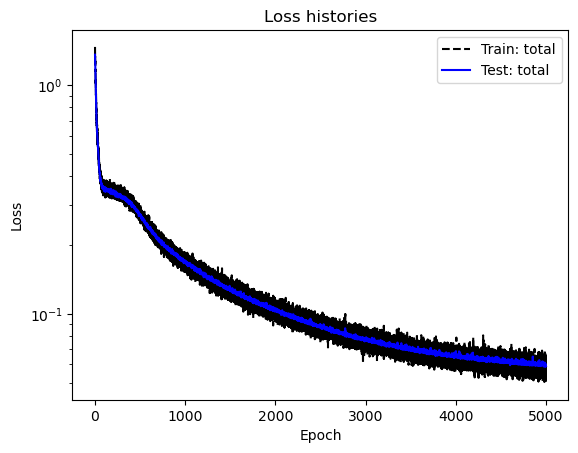

In [16]:
# Plot loss history
plt.plot(train_epoch_history, train_loss_history, "--k")
plt.plot(test_epoch_history, test_loss_history, "-b")
#plt.plot(test_reconstruction_loss_history, "-c")
plt.legend(['Train: total', 'Test: total',' Test: recon.'])
plt.yscale('log');
plt.xlabel('Epoch');
plt.ylabel('Loss');
plt.title('Loss histories');

In [18]:
# Generating predictions on the test set 
n_samples = 3000   # samples drawn per test point (for distribution estimation)
model.eval()

# Collect all predictions: shape (n_test, n_samples, 9)
all_preds = []
with torch.no_grad():
    for i in range(len(tensor_target_test)):
        c = tensor_condition_test[i]          # (4,)
        preds = model.sample_latent_space_given(c, n_samples)  # (n_samples, 9)
        all_preds.append(preds.numpy())

all_preds = np.array(all_preds)   # (n_test, n_samples, 9)

# Marginal expectation = mean over the n_samples axis
pred_means = all_preds.mean(axis=1)   # (n_test, 9)

# De-normalise both predictions and ground truth
pred_means_denorm = denormalise_target(pred_means)
true_denorm       = denormalise_target(norm_target_test.values)





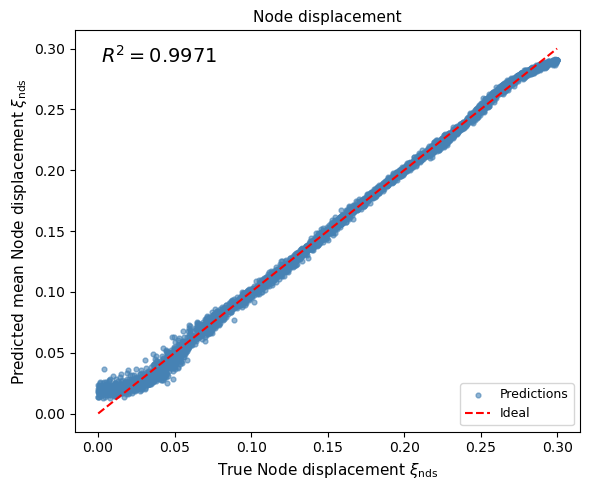

Saved: marginal_expectation_inverse_ndv.png


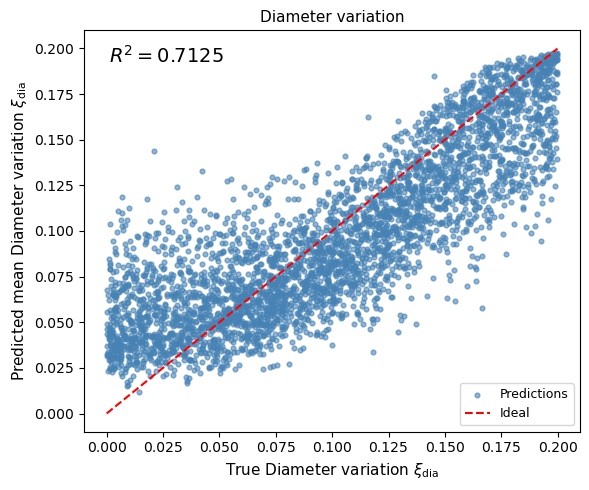

Saved: marginal_expectation_inverse_dmt.png


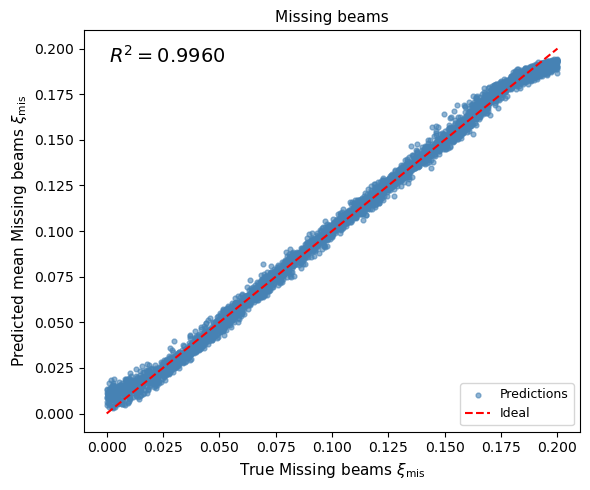

Saved: marginal_expectation_inverse_mis.png


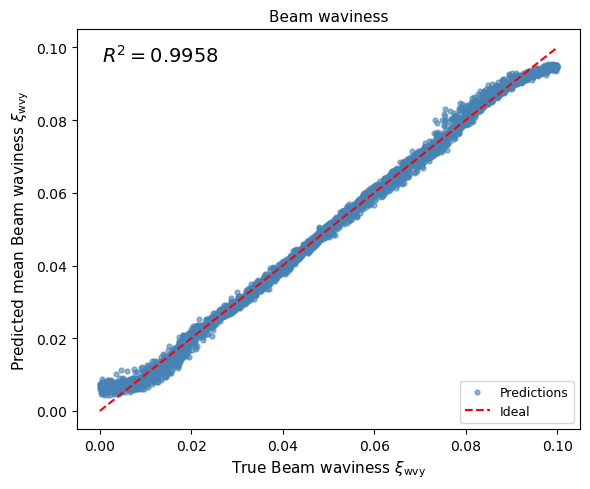

Saved: marginal_expectation_inverse_wvy.png


In [35]:
for i, imp in enumerate(imperfection_columns):
    fig, ax = plt.subplots(figsize=(6, 5))

    x = true_denorm[:, i]
    y = pred_means_denorm[:, i]

    ax.scatter(x, y, s=12, alpha=0.6, color='steelblue', label='Predictions')

    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Ideal')

    ss_res = np.sum((y - x) ** 2)
    ss_tot = np.sum((x - x.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    ax.text(0.05, 0.92, f'$R^2 = {r2:.4f}$', transform=ax.transAxes, fontsize=14)

    ax.set_xlabel(f'True {imp_xlabels.get(imp, imp)}', fontsize=11)
    ax.set_ylabel(f'Predicted mean {imp_xlabels.get(imp, imp)}', fontsize=11)
    ax.set_title(imp_titles.get(imp, imp), fontsize=11)
    ax.legend(fontsize=9)

    plt.tight_layout()
    fname = f'marginal_expectation_inverse_{imp}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}")

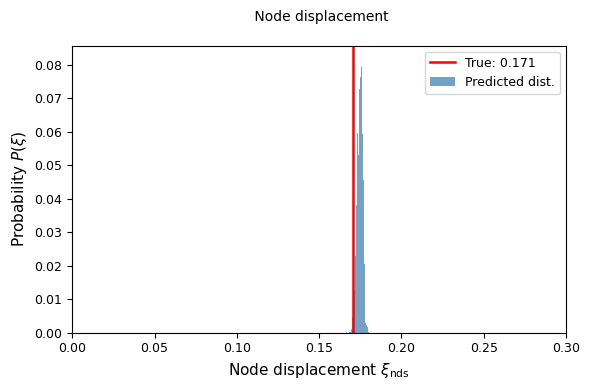

Saved: inverse_predicted_ndv_idx3767.png


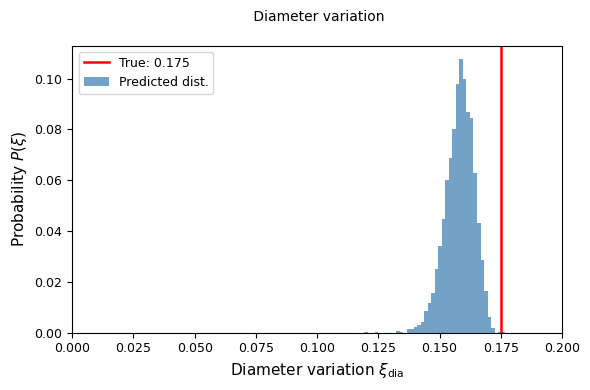

Saved: inverse_predicted_dmt_idx3767.png


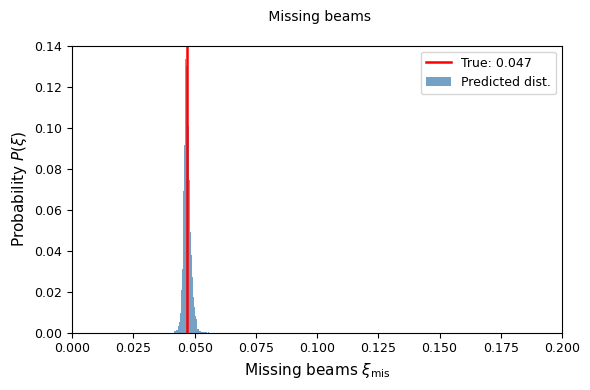

Saved: inverse_predicted_mis_idx3767.png


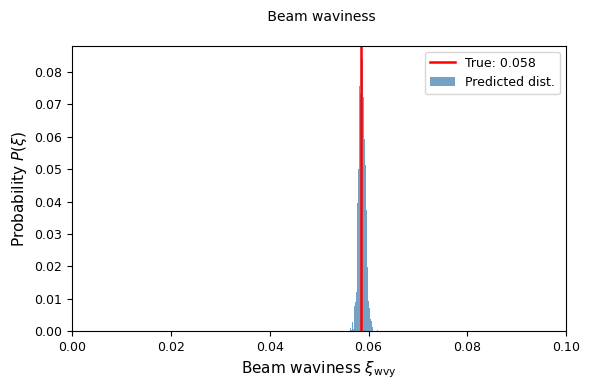

Saved: inverse_predicted_wvy_idx3767.png

Condition (test sample idx=3767):
$E_1$=259.798   $E_2$=472.948   $E_3$=189.331   $\nu_1$=0.022   $\nu_2$=-0.316   $\nu_3$=-0.309   $G_1$=4.482   $G_2$=336.156   $G_3$=133.712


In [37]:
# predicted imperfection distribution
# Given a set of measured mechanical properties (condition), the CVAE samples
# 3000 possible imperfection configurations. Each histogram shows the probability
# that a given imperfection parameter takes a value in that bin.
# The red line is the true (ground-truth) imperfection value.

imp_xlabels = {
    'ndv': 'Node displacement $\\xi_\\mathrm{nds}$',
    'dmt': 'Diameter variation $\\xi_\\mathrm{dia}$',
    'mis': 'Missing beams $\\xi_\\mathrm{mis}$',
    'wvy': 'Beam waviness $\\xi_\\mathrm{wvy}$',
}
imp_titles = {
    'ndv': 'Node displacement',
    'dmt': 'Diameter variation',
    'mis': 'Missing beams',
    'wvy': 'Beam waviness',
}
prop_labels = {
    'E1': '$E_1$', 'E2': '$E_2$', 'E3': '$E_3$',
    'V1': '$\\nu_1$', 'V2': '$\\nu_2$', 'V3': '$\\nu_3$',
    'G1': '$G_1$', 'G2': '$G_2$', 'G3': '$G_3$',
}
imp_xlims = {
    'ndv': (0, 0.3),
    'mis': (0, 0.2),
    'wvy': (0, 0.1),
    'dmt': (0, 0.2),
}

for i, imp in enumerate(imperfection_columns):
    fig, ax = plt.subplots(figsize=(6, 4))

    # probability mass histogram 
    counts, bin_edges = np.histogram(preds_sample_denorm[:, i], bins=40)
    probs     = counts / counts.sum()
    bin_width = bin_edges[1] - bin_edges[0]
    ax.bar(bin_edges[:-1], probs, width=bin_width,
           color='steelblue', alpha=0.75, align='edge', label='Predicted dist.')

    #  true value 
    ax.axvline(true_imp[i], color='red', lw=1.8, label=f'True: {true_imp[i]:.3f}')

    #  labels
    ax.set_xlabel(imp_xlabels.get(imp, imp), fontsize=11)
    ax.set_ylabel('Probability $P(\\xi)$', fontsize=11)
    ax.set_xlim(*imp_xlims[imp])
    ax.tick_params(labelsize=9)
    ax.legend(fontsize=9)

    # title with condition
    mech_vals = denormalise_condition(norm_condition_test.values[idx])
    title_str = '   '.join([f'{prop_labels.get(col, col)}={mech_vals[j]:.3f}'
                            for j, col in enumerate(mechanical_properties_columns)])
    ax.set_title(
        f' {imp_titles.get(imp, imp)}\n',
        fontsize=10
    ) # Comment out for the report 

    plt.tight_layout()
    fname = f'inverse_predicted_{imp}_idx{idx}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}")

# Print condition once after all plots
mech_vals = denormalise_condition(norm_condition_test.values[idx])
title_str = '   '.join([f'{prop_labels.get(col, col)}={mech_vals[j]:.3f}'
                        for j, col in enumerate(mechanical_properties_columns)])
print(f"\nCondition (test sample idx={idx}):\n{title_str}")

